In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path("../data/raw")

date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders      = pd.read_csv(RAW / "olist_orders_dataset.csv", parse_dates=date_cols)
customers   = pd.read_csv(RAW / "olist_customers_dataset.csv")
items       = pd.read_csv(RAW / "olist_order_items_dataset.csv")
payments    = pd.read_csv(RAW / "olist_order_payments_dataset.csv")
reviews     = pd.read_csv(RAW / "olist_order_reviews_dataset.csv")
products    = pd.read_csv(RAW / "olist_products_dataset.csv")
sellers     = pd.read_csv(RAW / "olist_sellers_dataset.csv")
translation = pd.read_csv(RAW / "product_category_name_translation.csv")

tables = {
    "orders": orders, "customers": customers, "items": items,
    "payments": payments, "reviews": reviews, "products": products,
    "sellers": sellers, "translation": translation,
}
for name, df in tables.items():
    print(f"{name:12} {df.shape}")

orders       (99441, 8)
customers    (99441, 5)
items        (112650, 7)
payments     (103886, 5)
reviews      (99224, 7)
products     (32951, 9)
sellers      (3095, 4)
translation  (71, 2)


In [2]:
for name, df in tables.items():
    miss = df.isna().sum()
    miss = miss[miss > 0]
    if len(miss):
        print(f"\n--- {name} ---")
        print(pd.DataFrame({"missing": miss, "percent": (miss / len(df) * 100).round(2)}))


--- orders ---
                               missing  percent
order_approved_at                  160     0.16
order_delivered_carrier_date      1783     1.79
order_delivered_customer_date     2965     2.98

--- reviews ---
                        missing  percent
review_comment_title      87656    88.34
review_comment_message    58247    58.70

--- products ---
                            missing  percent
product_category_name           610     1.85
product_name_lenght             610     1.85
product_description_lenght      610     1.85
product_photos_qty              610     1.85
product_weight_g                  2     0.01
product_length_cm                 2     0.01
product_height_cm                 2     0.01
product_width_cm                  2     0.01


In [3]:
for name, df in tables.items():
    print(f"{name:12} duplicate rows: {df.duplicated().sum()}")

print("\nDuplicate review_id values:", reviews["review_id"].duplicated().sum())
print("Duplicate order_id in orders:", orders["order_id"].duplicated().sum())

orders       duplicate rows: 0
customers    duplicate rows: 0
items        duplicate rows: 0
payments     duplicate rows: 0
reviews      duplicate rows: 0
products     duplicate rows: 0
sellers      duplicate rows: 0
translation  duplicate rows: 0

Duplicate review_id values: 814
Duplicate order_id in orders: 0


In [4]:
print(orders["order_status"].value_counts())

print("\nMissing delivery date, status ke hisaab se:")
print(orders[orders["order_delivered_customer_date"].isna()]["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing delivery date, status ke hisaab se:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [5]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"] - orders["order_estimated_delivery_date"]
).dt.days

orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.days

orders["is_late"] = (
    (orders["order_delivered_customer_date"] > orders["order_estimated_delivery_date"])
    .astype("boolean")
    .mask(orders["order_delivered_customer_date"].isna())
)

orders["order_month"] = orders["order_purchase_timestamp"].dt.to_period("M").astype(str)

orders[["order_id", "delivery_time_days", "delivery_delay_days", "is_late", "order_month"]].head()

,order_id,delivery_time_days,delivery_delay_days,is_late,order_month
0,e481f51cbdc54678b7cc49136f2d6af7,8.0,-8.0,False,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,13.0,-6.0,False,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,9.0,-18.0,False,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,13.0,-13.0,False,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,2.0,-10.0,False,2018-02


In [6]:
delivered = orders[
    (orders["order_status"] == "delivered")
    & orders["order_delivered_customer_date"].notna()
].copy()

print("Delivered orders:", len(delivered))
print("On-time %:", round((~delivered["is_late"].astype(bool)).mean() * 100, 2))
print(delivered[["delivery_time_days", "delivery_delay_days"]].describe().round(1))

Delivered orders: 96470
On-time %: 91.89
       delivery_time_days  delivery_delay_days
count             96470.0              96470.0
mean                 12.1                -11.9
std                   9.6                 10.2
min                   0.0               -147.0
25%                   6.0                -17.0
50%                  10.0                -12.0
75%                  15.0                 -7.0
max                 209.0                188.0


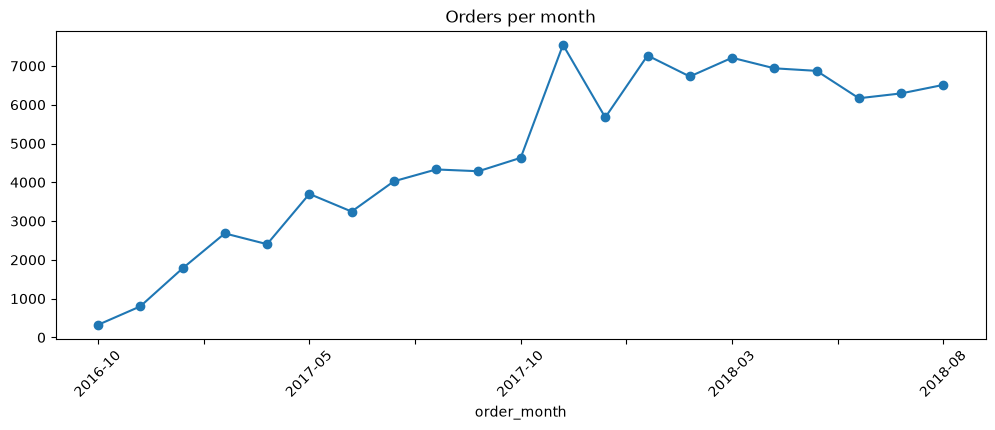

In [7]:
monthly = orders.groupby("order_month").size()
monthly = monthly[monthly > 100]   # shuru aur aakhri ke bahut kam order wale mahine hata diye

monthly.plot(kind="line", marker="o", figsize=(12, 4), title="Orders per month")
plt.xticks(rotation=45)
plt.show()

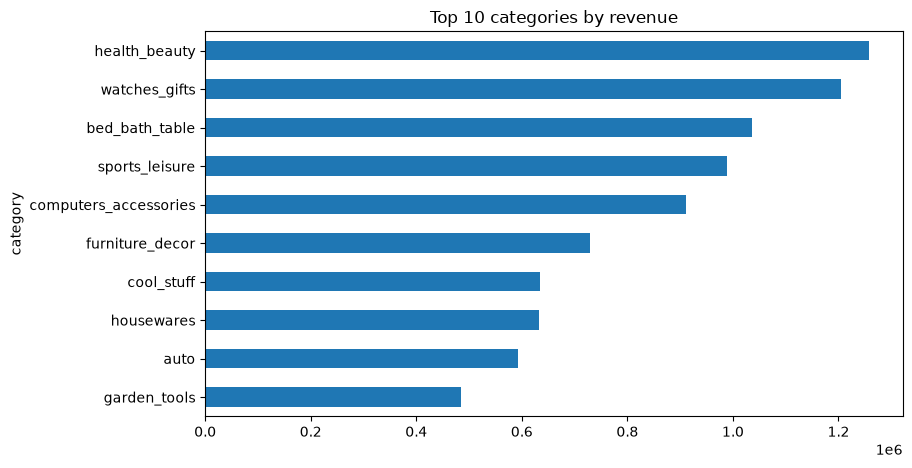

In [8]:
cat = (
    items.merge(products[["product_id", "product_category_name"]], on="product_id", how="left")
         .merge(translation, on="product_category_name", how="left")
)
cat["category"] = (
    cat["product_category_name_english"]
    .fillna(cat["product_category_name"])
    .fillna("unknown")
)

top = cat.groupby("category")["price"].sum().sort_values(ascending=False).head(10)
top.sort_values().plot(kind="barh", figsize=(9, 5), title="Top 10 categories by revenue")
plt.show()

In [9]:
d = delivered.merge(customers[["customer_id", "customer_state"]], on="customer_id")
late_state = (
    d.groupby("customer_state")["is_late"].mean().mul(100).round(1)
     .sort_values(ascending=False).head(10)
)
print(late_state)

customer_state
AL    23.9
MA    19.7
PI    16.0
CE    15.3
SE    15.2
BA    14.0
RJ    13.5
TO    12.8
PA    12.4
RR    12.2
Name: is_late, dtype: Float64
